# Variational Autoencoders Part 3: VAE extensions

**Vanessa Gómez Verdejo,  Pablo Martínez Olmos, Alejandro Lancho Serrano**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='http://www.tsc.uc3m.es/~emipar/BBVA/INTRO/img/logo_uc3m_foot.jpg' width=400 />

In [25]:
import numpy as np
import matplotlib.pyplot as plt

In [26]:
!pip install pytorch-model-summary

## References and Acknowledgments

This notebook introduces Variational Autoencoders (VAEs) and is inspired by several excellent sources. In particular, we recommend the following references for a deeper understanding:

- **Bishop, C. M.** _Deep Learning: foundations and concepts_. Chapter on Autoencoders.
- **Tomczak, J. M.** _Deep Generative Modeling_. Chapter on Variational Autoencoders.

Some of the figures, illustrations and implementations included in this notebook have been adapted or directly taken from these references for educational purposes.


# Introduction to Latent Variable Models  



## Mathematical Formulation  

Instead of modeling $\bf x $ directly, we introduce a **latent variable** $\bf z $ that represents hidden factors in the data. Mathematically, we consider a high-dimensional object ${\bf x}  \in \mathcal{X}^D $ (e.g., an image where pixel values belong to $\mathcal{X} = \{0, 1, \dots, 255\} $) and a lower-dimensional latent variable ${\bf z} \in \mathcal{Z}^M $ (e.g., $ \mathcal{Z} = \mathbb{R}^M $). We can refer to $ \mathcal{Z}^M $ as a **low-dimensional manifold** or the **latent space**.  

The generative process is then expressed as:  

1. **Sample a latent variable**:  
   $$   {\bf z} \sim p({\bf z})$$
2. **Generate an observation from the latent variable**:  
    $$    \mathbf{x}\sim p(\mathbf{x}\mid \mathbf{z},\theta)    $$

<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_1.png" width=60%>

This formulation naturally follows the intuitive generative process described earlier. However, during training, we only have access to ${\bf x}$, not ${\bf z}$. According to probabilistic inference, we must marginalize out the unknown latent variable ${\bf z}$, leading to the **marginal likelihood function**:  

$$
p({\bf x}\mid \theta) = \int p({\bf x} \mid {\bf z}, \theta) p({\bf z}) \, d{\bf z}
$$

In practice, we do not have just a single observation $ \mathbf{x} $, but rather a dataset with $ N$ independent observations $ \{ \mathbf{x}^{(i)} \}_{i=1}^{N} $. Given these observations, we adjust the model parameters by maximizing the **joint likelihood** over all data points:  

$$
p(\mathbf{x}^{(1)}, \mathbf{x}^{(2)}, \dots, \mathbf{x}^{(N)}\mid \theta) = \prod_{i=1}^{N} p(\mathbf{x}^{(i)} \mid \theta)
$$

Since each $ p(\mathbf{x}^{(i)}) $ is computed by marginalizing over the latent variable $ \mathbf{z}^{(i)}$, the marginal likelihood function takes the form:  

$$
\mathcal{L}(\theta) = \prod_{i=1}^{N} \int p(\mathbf{x}^{(i)} \mid \mathbf{z}^{(i)}, \theta) p(\mathbf{z}^{(i)}) \, d\mathbf{z}^{(i)}
$$

where $\theta$ are the model parameters that allow us to relate the latent variables to the observations. To facilitate optimization, it is common to maximize the **log-likelihood**, which transforms the product into a sum:  

$$
\log \mathcal{L}(\theta) = \sum_{i=1}^{N} \log \int p(\mathbf{x}^{(i)} \mid \mathbf{z}^{(i)}; \theta) p(\mathbf{z}^{(i)}) \, d\mathbf{z}^{(i)}
$$



## Challenges and Approaches  

But, **how can we compute this integral?**

$$
p({\bf x}\mid \theta) = \int p({\bf x} \mid {\bf z}, \theta) p({\bf z}) \, d{\bf z}
$$

In general, evaluating this integral exactly is challenging. There are two main approaches:  

1. **If the integral is tractable**, we can compute $p({\bf x})$ exactly. A specific case where this is possible is **Probabilistic PCA**.  
2. **If the integral is intractable**, we need approximate inference techniques. One of the most powerful methods for efficiently approximating this integral is **Variational Inference (VI)**. This idea is at the core of **Variational Autoencoders (VAEs)**.


# Variational Autoencoders: review



## Training a VAE


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_6.png" width=70%>

**Pseudocode**:

1. Take $\mathbf{x}_i$ and apply the encoder network to obtain $\boldsymbol{\mu}_\phi(\mathbf{x}_i)$ and $\log \boldsymbol{\sigma}^2_\phi(\mathbf{x}_i)$.
2. Calculate $\mathbf{z}_{\phi,i}$ by applying the **reparameterization trick** (we consider $L=1$):  
   $$\mathbf{z}_{\phi,i} = \boldsymbol{\mu}_\phi(\mathbf{x}_i) + \boldsymbol{\sigma}_\phi(\mathbf{x}_i) \odot \boldsymbol{\epsilon}, \quad \text{where } \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}).$$
3. Apply the decoder network to $\mathbf{z}_{\phi,i}$ to get the reconstruction probability distribution $p_\theta(\mathbf{x}_i \mid \mathbf{z}_{\phi,i})$.
4. Compute the ELBO by plugging in $\mathbf{x}_i$, $\mathbf{z}_{\phi,i}$, $\boldsymbol{\mu}_\phi(\mathbf{x}_i)$, and $\log \boldsymbol{\sigma}^2_\phi(\mathbf{x}_i)$ into the expression:

$$
\mathcal{L}(\theta, \phi; \mathbf{x}_i) \approx \log p_\theta(\mathbf{x}_i \mid \mathbf{z}_{\phi,i}) - \mathrm{KL}\left( q_\phi(\mathbf{z} \mid \mathbf{x}_i) \, \| \, p(\mathbf{z}) \right).
$$

This process is repeated for each data point (or with subsets of data mini-batches), and the parameters $\theta$ and $\phi$ are updated using gradient-based optimization to maximize the ELBO over the dataset.



## The generative process

<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_3.png" width=60%>

## Some utilities


In [27]:
from torchvision import datasets, transforms
from torch.utils.data import Dataset

class MNIST(Dataset):
    def __init__(self, mode='train', transforms=None):
        if mode == 'train':
            self.data = datasets.MNIST(root='.', train=True, download=True, transform=transforms)
        else: # Using test split for evaluation
            self.data = datasets.MNIST(root='.', train=False, download=True, transform=transforms)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, _ = self.data[idx]
        # Flatten the 28x28 image to a 784-dimensional vector
        return img.view(-1)

In [28]:
import torch
import torch.nn as nn

# Define some constants
PI = torch.from_numpy(np.asarray(np.pi))
EPS = 1.e-5

class Encoder(nn.Module):
    def __init__(self, encoder_net):
        super(Encoder, self).__init__()

        # The encoder network (e.g., MLP) that outputs concatenated [mu, log_var]
        self.encoder = encoder_net

    def reparameterization(self, mu, log_var):
        # Reparameterization trick:
        # Sample z ~ N(mu, sigma^2) using z = mu + sigma * epsilon,
        # where epsilon ~ N(0, I)
        std = torch.exp(0.5 * log_var)        # Convert log variance to standard deviation
        eps = torch.randn_like(std)           # Sample epsilon with the same shape as std (L=1)
        return mu + std * eps                 # Sample z

    def encode(self, x):
        # Forward input x through the encoder network to get mu and log_var
        h_e = self.encoder(x)                 # Output is of size 2M
        mu_e, log_var_e = torch.chunk(h_e, 2, dim=1)  # Split into two parts: mean and log variance
        return mu_e, log_var_e

    def sample(self, x=None, mu_e=None, log_var_e=None):
        # Return a sample from the approximate posterior
        # Can either compute mu/log_var from x or take them as input
        if (mu_e is None) and (log_var_e is None):
            mu_e, log_var_e = self.encode(x)
        else:
            if (mu_e is None) or (log_var_e is None):
                raise ValueError('mu and log_var can\'t be None!')
        z = self.reparameterization(mu_e, log_var_e)
        return z


In [29]:
import warnings

import torch.nn.functional as F

class BernoulliDecoder(nn.Module):
    def __init__(self, decoder_net):
        super(BernoulliDecoder, self).__init__()
        self.decoder = decoder_net

    def decode(self, z):
        logits = self.decoder(z)
        probs = torch.sigmoid(logits)
        return probs

    def sample(self, z):
        probs = self.decode(z)
        return probs  # Return probabilities in [0,1]

    def log_prob(self, x, z):
        theta = self.decode(z)
        # BCE
        # Check x values are between 0 and 1
        if torch.any(x < 0) or torch.any(x > 1):
            x = torch.clamp(x, 0, 1)  # Clamp to [0,1] for soft Bernoulli
            warnings.warn("Clamping x to [0,1] for Bernoulli log_prob computation.")
            #raise ValueError('Input x must be in the range [0, 1] for Bernoulli log_prob computation.')
        log_prob = -F.binary_cross_entropy(theta, x, reduction='none').sum(dim=1)
        return log_prob

In [30]:
class Prior(nn.Module):
    def __init__(self, M):
        super(Prior, self).__init__()
        # M is the dimensionality of the latent space
        self.M = M

    def sample(self, batch_size):
        # Sample from a standard normal distribution (mean=0, std=1)
        z = torch.randn((batch_size, self.M))  # Shape: (batch_size, latent_dim)
        return z


In [31]:
import torch
import torch.nn as nn


def evaluation(test_loader, model_best, epoch=None):
    # EVALUATION (handles models that return components)
    model_best.eval()
    total_loss = 0.
    total_re = 0.
    total_kl = 0.
    N = 0.

    for indx_batch, test_batch in enumerate(test_loader):
        out = None
        # try to request components explicitly if possible
        try:
            out = model_best.forward(test_batch, return_components=True)
        except TypeError:
            out = model_best.forward(test_batch)

        if isinstance(out, tuple):
            loss_t = out[0]
            if len(out) >= 3:
                re_t = out[1]
                kl_t = out[2]
            else:
                re_t, kl_t = 0., 0.
        else:
            loss_t = out
            re_t, kl_t = 0., 0.

        total_loss += loss_t.item()
        total_re += re_t if not isinstance(re_t, torch.Tensor) else re_t.item()
        total_kl += kl_t if not isinstance(kl_t, torch.Tensor) else kl_t.item()
        N += test_batch.shape[0]

    avg_loss = total_loss / N
    avg_re = total_re / N
    avg_kl = total_kl / N

    if epoch is None:
        print(f'FINAL LOSS: nll={avg_loss}')
    else:
        print(f'Epoch: {epoch}, val nll={avg_loss}, RE={avg_re}, KL={avg_kl}')

    return avg_loss, avg_re, avg_kl


def training(max_patience, num_epochs, model, optimizer, training_loader, val_loader, scheduler=None, plot = True):
    nll_val = []
    re_val = []
    kl_val = []
    best_nll = 1000
    patience = 0

    # Main loop
    for e in range(num_epochs):
        # TRAINING
        model.train()
        for indx_batch, batch in enumerate(training_loader):
            # request components if model supports them
            try:
                out = model.forward(batch, return_components=True)
            except TypeError:
                out = model.forward(batch)

            if isinstance(out, tuple):
                loss = out[0]
            else:
                loss = out

            optimizer.zero_grad()
            loss.backward(retain_graph=True)
            optimizer.step()

        # Step the scheduler after each epoch
        if scheduler is not None:
            scheduler.step()

        # Validation
        #if e % 5 == 0:  # validar cada 5 épocas
        loss_val, re_val_e, kl_val_e = evaluation(val_loader, model_best=model, epoch=e)
        nll_val.append(loss_val)  # save for plotting
        re_val.append(re_val_e)
        kl_val.append(kl_val_e)

        if e == 0:
            best_nll = loss_val
            best_model = model
        else:
            if loss_val < best_nll:
                best_nll = loss_val
                patience = 0
                best_model = model
            else:
                patience = patience + 1

        if patience > max_patience:
            break

    nll_val = np.asarray(nll_val)
    re_val = np.asarray(re_val)
    kl_val = np.asarray(kl_val)

    if plot:
        # Plot the curves in separate subplots for clarity
        fig, axs = plt.subplots(3, 1, sharex=True, figsize=(6, 9))
        epochs = np.arange(len(nll_val))

        axs[0].plot(epochs, nll_val, linewidth=3, color='C0')
        axs[0].set_ylabel('nll (neg ELBO)')
        axs[0].set_title('Training metrics per epoch')

        axs[1].plot(epochs, re_val, linewidth=2, color='C1')
        axs[1].set_ylabel('RE avg')

        axs[2].plot(epochs, kl_val, linewidth=2, color='C2')
        axs[2].set_ylabel('KL avg')
        axs[2].set_xlabel('epochs')

        plt.tight_layout()
        plt.show()

    return nll_val, re_val, kl_val, best_model


def samples_generated(model_best):

    model_best.eval()
    num_x = 4
    num_y = 4
    x = model_best.sample(num_x * num_y)
    x = x.detach().numpy()

    fig, ax = plt.subplots(num_x, num_y)
    for i, ax in enumerate(ax.flatten()):
        plottable_image = np.reshape(x[i], (28, 28))
        ax.imshow(plottable_image, cmap='gray')
        ax.axis('off')


# Limitations of standard VAEs

While Variational Autoencoders (VAEs) are a powerful framework for generative modeling and representation learning, the **standard VAE formulation has several known limitations** that motivate the development of more advanced variants.

### 1. **Blurry Reconstructions**

VAEs often produce reconstructions and samples that appear overly smooth or blurry, particularly in image generation tasks. This limitation arises from multiple interacting factors:

*    First, the choice of likelihood (commonly a Gaussian with fixed variance) leads the decoder to produce mean estimates that average over uncertainty. When the data distribution is multimodal (e.g., sharp edges or textures), this averaging effect results in blurred outputs.

* Second, standard decoders are often not expressive enough to accurately model the conditional data distribution $p(x∣z)$. A simple convolutional or MLP decoder might not capture complex image structure or high-frequency details.

* Finally, the use of a simple prior, such as an isotropic Gaussian, can limit the capacity of the latent space to represent diverse modes of the data, further contributing to dull or homogenized outputs.


### 2. **Posterior Collapse**

* During training, the encoder might **ignore the input data**, and the learned latent variables $z$ become **independent of $x$**.
* This often happens when the decoder is **too powerful**, and the model learns to minimize the reconstruction loss without using the latent space (i.e., $q(z|x) \approx p(z)$).
* The result: the **KL divergence term collapses to zero**, and the VAE degenerates into a simple autoencoder.

### 3. **Limited Expressiveness of the Latent Space**

* The standard VAE assumes a **simple prior** over the latent variables, typically a **standard Gaussian**, which may not match the true distribution of latent representations.
* This can lead to **poor generation quality** and **unstructured latent spaces**, making the learned representations hard to interpret or use.

### 4. **Lack of Disentanglement**

* VAEs do not encourage latent variables to represent **independent or interpretable generative factors**.
* The learned latent codes are often **entangled**, meaning that changing one latent dimension can affect multiple generative aspects of the output in complex, coupled ways.



## VAE Variants

To address these issues, several VAE extensions have been proposed:

* **β-VAE**: Encourages disentangled latent representations by increasing the weight of the KL divergence term, promoting independence among latent dimensions.
* **GMM-VAE**: Uses a **Gaussian Mixture prior** instead of a single Gaussian to better model multimodal latent distributions, improving clustering and generation diversity.
* **VQ-VAE**: Replaces continuous latent variables with **discrete codes** from a learnable codebook, improving reconstruction sharpness and enabling symbolic representations.
* **Hierarchical VAE**: Introduces multiple layers of latent variables organized in a hierarchy. This allows the model to capture complex, multi-scale data structures, where high-level latent variables encode global features while lower-level ones capture local details. Hierarchical formulations improve flexibility and generative capacity, at the cost of more challenging inference.


Each of these models modifies the **objective function**, **prior**, or **latent structure** of the VAE to better align with desired properties such as disentanglement, diversity, and fidelity. In what follows, we will focus on β-VAE, GMM-VAE, and briefly on Hierarchical VAE and VQ-VAE.


## Hierarchical VAE with Two Latent Levels

Next diagram illustrates a **Hierarchical VAE** (HVAE) with two latent levels ($z_2 \to z_1 \to x$). It shows the **top-down generative process** and the **bottom-up inference process**, making it easier to compare with the standard VAE.

<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_8.png" width=40%>

* **Generative model:**

  $$
  p(x, z_1, z_2) = p(z_2)\,p(z_1 \mid z_2)\,p(x \mid z_1)
  $$

  Sample $z_2$ first, then $z_1$ conditioned on $z_2$, and finally $x$ conditioned on $z_1$.

* **Inference model:**

  $$
  q(z_1, z_2 \mid x) = q(z_1 \mid x)\,q(z_2 \mid z_1, x)
  $$

  Inference proceeds bottom-up: first infer $z_1$ from the input $x$, then infer $z_2$ given $z_1$.


This architecture allows the VAE to capture **multi-scale hierarchical features**:

* $z_2$: global, abstract factors (e.g., style, shape).
* $z_1$: more local, fine-grained details (e.g., texture, edges).


 Here, we will not go deeper into hierarchical VAEs, since they will be revisited in a later session when discussing diffusion models, which can be understood as a particular instance of hierarchical generative model with $T$ hierarchical levels.

# $\beta$-VAE

One key limitation of standard VAEs is the **lack of disentanglement** in the latent space. The model learns a compressed representation of the data, but the latent variables typically capture **entangled** features, i.e., each dimension of the latent vector can influence multiple generative factors in complex and unpredictable ways.

In many applications, we desire **disentangled representations**, where **each latent dimension corresponds to an independent and interpretable factor of variation** in the data (e.g., object orientation, lighting, shape, etc.). Disentangled representations are useful for:

* Interpretability and controllability in generative models
* Downstream tasks such as clustering or transfer learning
* Discovering structure in unlabeled data


## The Formulation

The **β-VAE** introduces a simple yet powerful modification to the standard VAE objective by **up-weighting the KL divergence term** with a hyperparameter $\beta \geq 1$:

$$
\mathcal{L}_{\beta\text{-VAE}} = \mathbb{E}_{q(z|x)}[\log p(x|z)] - \beta \, \text{KL}(q(z|x) \,||\, p(z))
$$

This adjustment changes the trade-off between **reconstruction fidelity** and **adherence to the prior**:

* $\beta = 1$: recovers the standard VAE
* $\beta > 1$: puts more pressure on the latent space to match the prior, leading to **more factorized** and **disentangled** representations
* $\beta < 1$: can improve reconstruction but at the cost of latent regularization

Note that when $\beta > 1$, the KL term in the VAE objective is weighted more heavily. This forces the encoder’s distribution $q(z|x)$ to stay closer to the factorized prior $p(z) = \mathcal{N}(0, I)$. As a result:

* Latent dimensions are encouraged to be independent.

* Each dimension tends to capture a single generative factor, reducing entanglement.

* Reconstruction may slightly worsen, but the latent space becomes more interpretable.

In short, increasing $\beta$ trades some reconstruction quality for disentangled, more structured latent representations.

In [32]:
class BetaVAE(nn.Module):
    def __init__(self, encoder_net, decoder_net, beta=1.0, M=16):
        super(BetaVAE, self).__init__()

        self.encoder = Encoder(encoder_net=encoder_net)
        self.decoder =  BernoulliDecoder(decoder_net=decoder_net)
        self.prior = Prior(M=M)

        self.beta = beta

    def forward(self, x, return_components=False):
        # Encode
        mu_e, log_var_e = self.encoder.encode(x)
        z = self.encoder.sample(mu_e=mu_e, log_var_e=log_var_e)

        # Reconstruction log-likelihood per example
        RE = self.decoder.log_prob(x, z)  # shape: (batch_size,)

        # KL divergence between q(z|x) and p(z) per example
        KL = -0.5 * torch.sum(1 + log_var_e - mu_e.pow(2) - log_var_e.exp(), dim=1)  # shape: (batch_size,)

        # ELBO per example
        elbo = RE - self.beta * KL

        loss = -elbo.sum()  # negative ELBO (to minimize)

        if return_components:
            return loss, RE.sum(), KL.sum()
        else:
            return loss

    def compute_components(self, x):
        """
        Utility to compute and return loss, reconstruction term and KL term
        for a batch of inputs (no gradients).
        """
        with torch.no_grad():
            loss, RE, KL = self.forward(x, return_components=True)
        return {'loss': loss.item(), 'RE': RE.item(), 'KL': KL.item()}

    def sample(self, batch_size=64):
        z = self.prior.sample(batch_size=batch_size)
        return self.decoder.sample(z)


In [33]:
# Parameter definition

D = 28*28   # 784 input dimension
M = 8  # number of latents
hidden_layer_neurons = 128  # the number of neurons in encoder and decoder nets

lr = 1e-3#1e-3 # starting learning rate
num_epochs = 100 # max. number of epochs
max_patience = 10 # an early stopping is used, if training doesn't improve for longer than 20 epochs, it is stopped

batch_size = 128#64

In [34]:
from torch.utils.data import DataLoader

# Define dataloaders
mnist_transforms_nonorm = transforms.Compose([
    transforms.ToTensor(),  # Original values are in [0,1]
    # No normalization!
])

train_dataset = MNIST(mode='train', transforms=mnist_transforms_nonorm)
val_dataset = MNIST(mode='val', transforms=mnist_transforms_nonorm)
test_dataset = MNIST(mode='val', transforms=mnist_transforms_nonorm)

training_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Entrenando BetaVAE con beta=1.0
Epoch: 0, val nll=157.62479389648436, RE=-148.68340964355468, KL=8.94138727722168
Epoch: 1, val nll=135.16686694335937, RE=-122.77489149169922, KL=12.391975958251953
Epoch: 2, val nll=125.77790900878907, RE=-111.84458491210937, KL=13.933323324584961
Epoch: 3, val nll=122.25706397705078, RE=-107.79076008300781, KL=14.466303340148926
Epoch: 4, val nll=119.71368349609375, RE=-104.7866258178711, KL=14.92705765838623
Epoch: 5, val nll=118.20409166259766, RE=-103.30559099121093, KL=14.898501473999023
Epoch: 6, val nll=116.73032912597657, RE=-101.5738937866211, KL=15.15643603515625
Epoch: 7, val nll=115.31381096191406, RE=-99.83428706054687, KL=15.479524424743653
Epoch: 8, val nll=114.69115693359375, RE=-99.4886553955078, KL=15.202500418090821
Epoch: 9, val nll=114.01136981201172, RE=-98.99873869628907, KL=15.012631019592286
Epoch: 10, val nll=113.36195980224609, RE=-97.94328521728515, KL=15.418674221801759
Epoch: 11, val nll=112.81126556396484, RE=-97.01280479

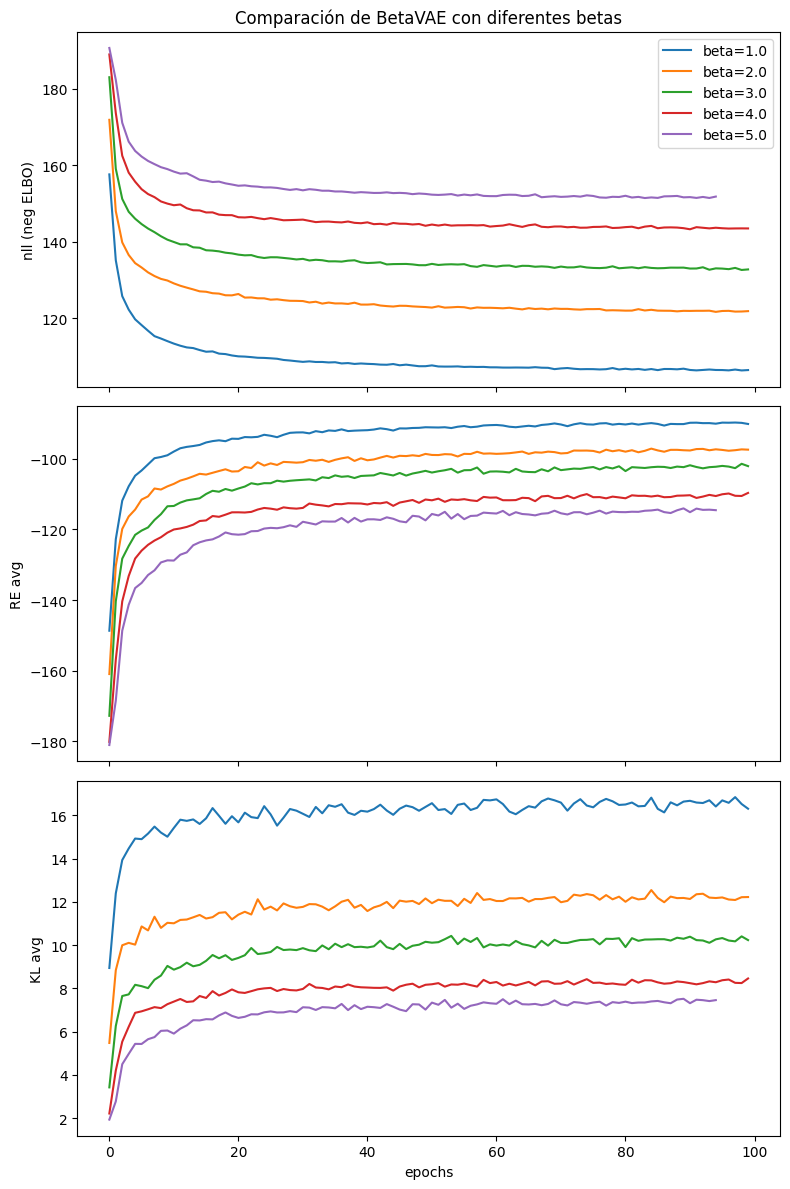

In [35]:
# Entrenar múltiples BetaVAE con diferentes betas y guardar resultados
beta_values = [1.0, 2.0, 3.0, 4.0, 5.0]
beta_results = {}

for beta in beta_values:
    print(f"Entrenando BetaVAE con beta={beta}")

    # Definir encoder y decoder
    beta_encoder = nn.Sequential(nn.Linear(D, hidden_layer_neurons), nn.LeakyReLU(),
                            nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
                            nn.Linear(hidden_layer_neurons, 2 * M))

    beta_decoder = nn.Sequential(nn.Linear(M, hidden_layer_neurons), nn.LeakyReLU(),
                            nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
                            nn.Linear(hidden_layer_neurons, D))

    # Modelo
    beta_model = BetaVAE(encoder_net=beta_encoder, decoder_net=beta_decoder, beta=beta, M=M)
    optimizer = torch.optim.Adam([p for p in beta_model.parameters() if p.requires_grad == True], lr=lr)

    # Entrenar
    nll_val, re_val, kl_val, best_model = training(max_patience=max_patience, num_epochs=num_epochs, model=beta_model, optimizer=optimizer,
                           training_loader=training_loader, val_loader=val_loader, plot =False)

    # Guardar resultados
    beta_results[f'beta_{beta}'] = {'nll': nll_val, 're': re_val, 'kl': kl_val, 'model': best_model}

# Ahora plotear juntos
fig, axs = plt.subplots(3, 1, sharex=True, figsize=(8, 12))

for beta in beta_values:
    nll = beta_results[f'beta_{beta}']['nll']
    re = beta_results[f'beta_{beta}']['re']
    kl = beta_results[f'beta_{beta}']['kl']
    epochs = np.arange(len(nll))
    label = f'beta={beta}'
    axs[0].plot(epochs, nll, label=label)
    axs[1].plot(epochs, re, label=label)
    axs[2].plot(epochs, kl, label=label)

axs[0].set_ylabel('nll (neg ELBO)')
axs[0].set_title('Comparación de BetaVAE con diferentes betas')
axs[0].legend()

axs[1].set_ylabel('RE avg')

axs[2].set_ylabel('KL avg')
axs[2].set_xlabel('epochs')

plt.tight_layout()
plt.show()


## Remarks:

The training curves illustrate the effect of the **β parameter in the β-VAE objective**, defined as:

$$
\mathcal{L}_{\beta\text{-VAE}} = \mathbb{E}_{q(z|x)}[\log p(x|z)] - \beta \, \text{KL}(q(z|x) \,||\, p(z))
$$
where the first term measures reconstruction quality and the second term regularizes the latent distribution toward the prior.

From the plots we can draw the following conclusions:

1. **Effect of β on reconstruction quality**  
   Smaller values of β (0.5 and 1) lead to lower negative ELBO values and better reconstruction error. This indicates that the model prioritizes reconstructing the input images accurately.

2. **Effect of β on KL divergence**  
   For small β values, the KL divergence is significantly larger. This means the encoder is actively using the latent variables to encode information about the input data.

3. **Strong regularization with large β values**  
   When β increases (5 and 10), the KL term is heavily penalized. As a result, the KL divergence becomes much smaller, meaning the latent variables are pushed closer to the prior distribution.

4. **Capacity trade-off**  
   Increasing β reduces the amount of information transmitted through the latent space. This leads to worse reconstruction performance but produces a more regularized latent representation.

5. **Overall observation**  
   The curves clearly show the fundamental trade-off in β-VAEs:
   - small β → better reconstructions and higher latent capacity  
   - large β → stronger regularization but reduced information in the latent space


In [36]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def latent_traversal(model, latent_dim=None, n_steps=10, z_range=(-3, 3)):
    model.eval()

    # Detect latent dimension if not provided
    if latent_dim is None:
        latent_dim = model.prior.M

    # Values for each latent
    traversal_values = np.linspace(*z_range, n_steps)

    # Inicialialize z (all zeros) and later modify each dimension (one by one)
    z_base = torch.zeros(1, latent_dim)

    fig, axes = plt.subplots(latent_dim, n_steps, figsize=(n_steps, latent_dim))

    for i in range(latent_dim):
        for j, val in enumerate(traversal_values):
            z = z_base.clone()
            z[0, i] = val

            # Decode
            with torch.no_grad():
                x_hat = model.decoder.sample(z.to(next(model.parameters()).device))
                x_hat = x_hat.cpu().numpy()

            # Plot
            image = x_hat[0].reshape(28, 28)
            ax = axes[i, j] if latent_dim > 1 else axes[j]
            ax.imshow(image, cmap="gray")
            ax.axis("off")

    plt.tight_layout()
    plt.show()


beta: 1.0


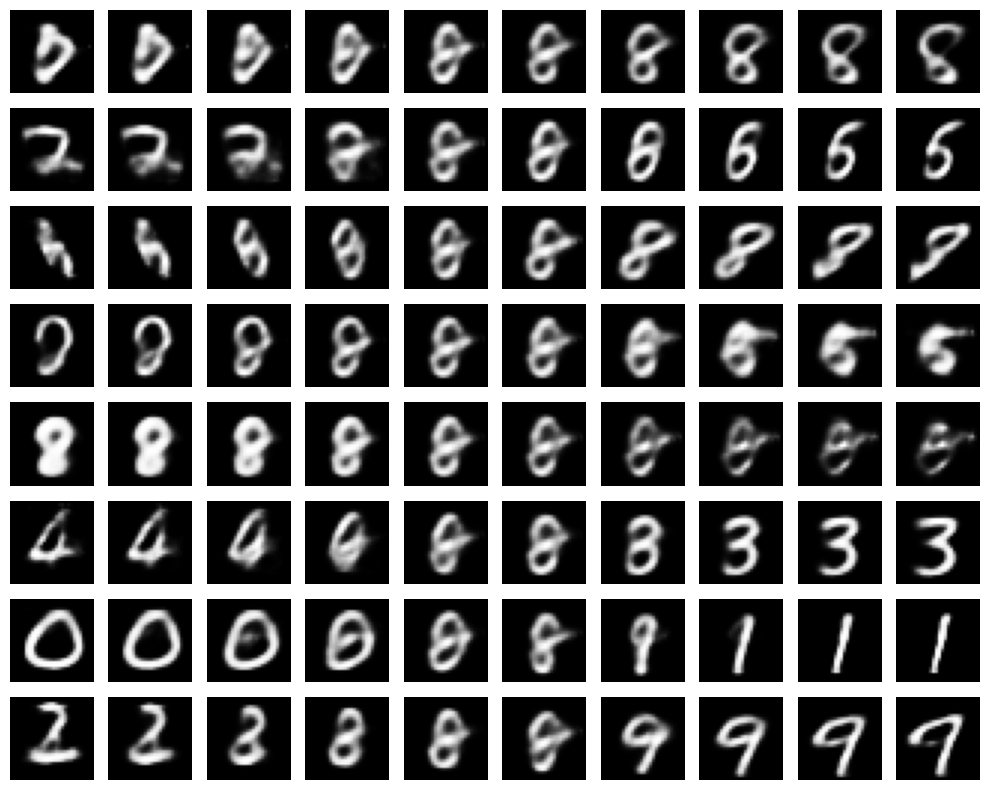

beta: 2.0


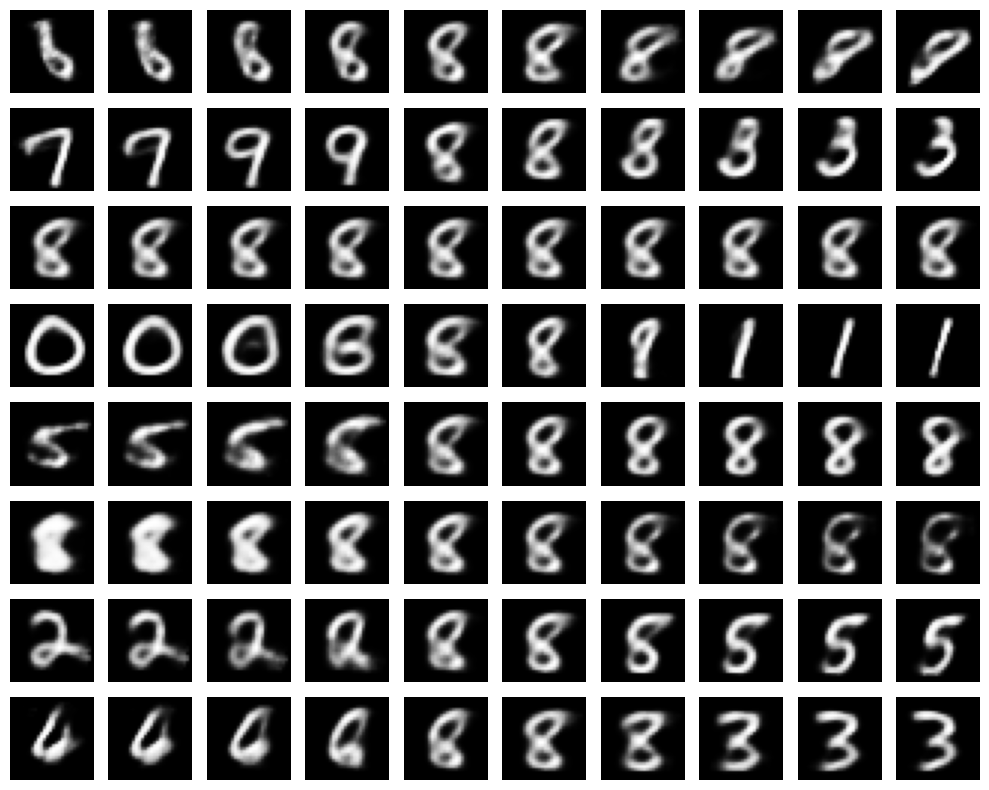

beta: 3.0


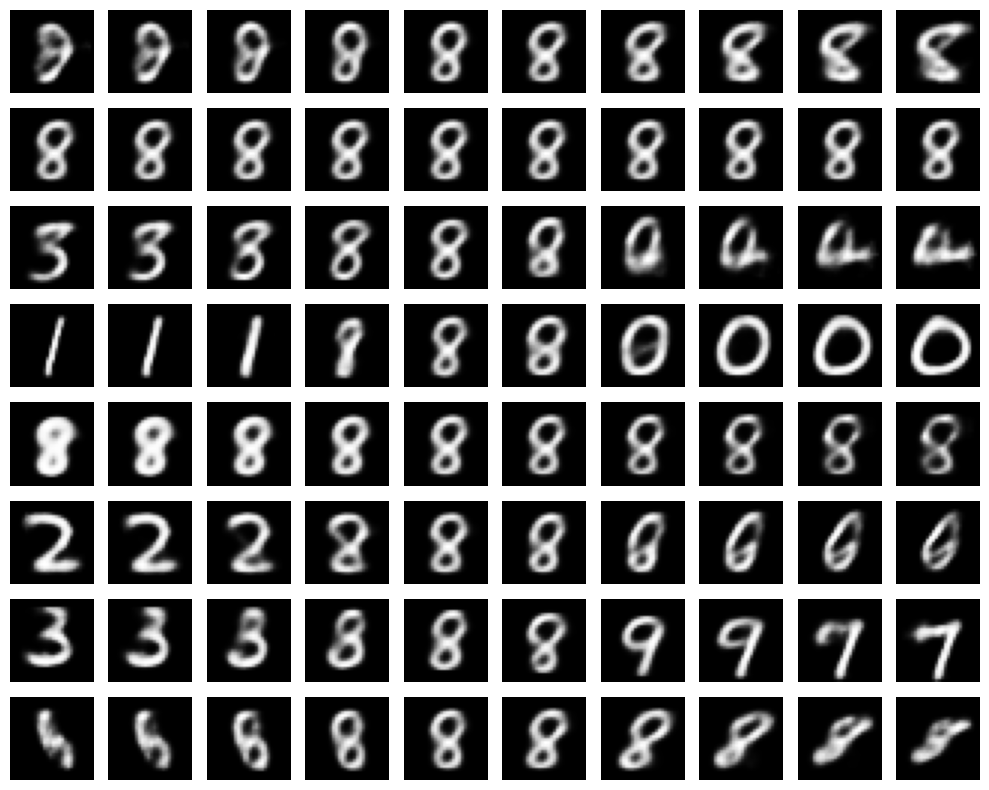

beta: 4.0


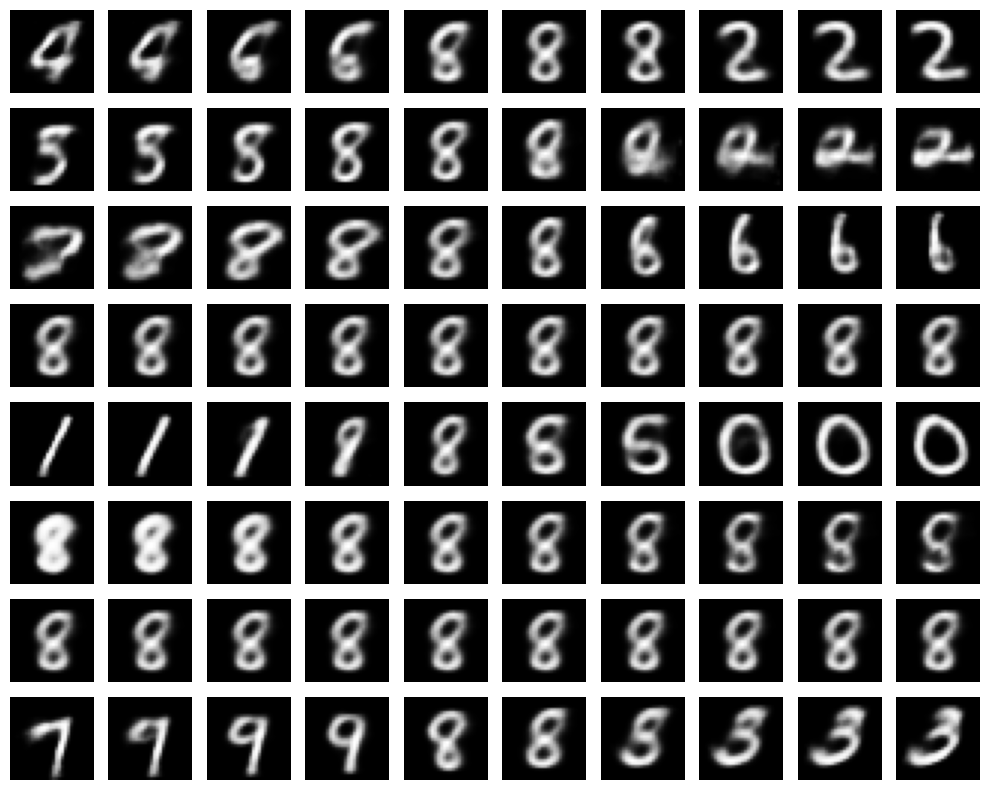

beta: 5.0


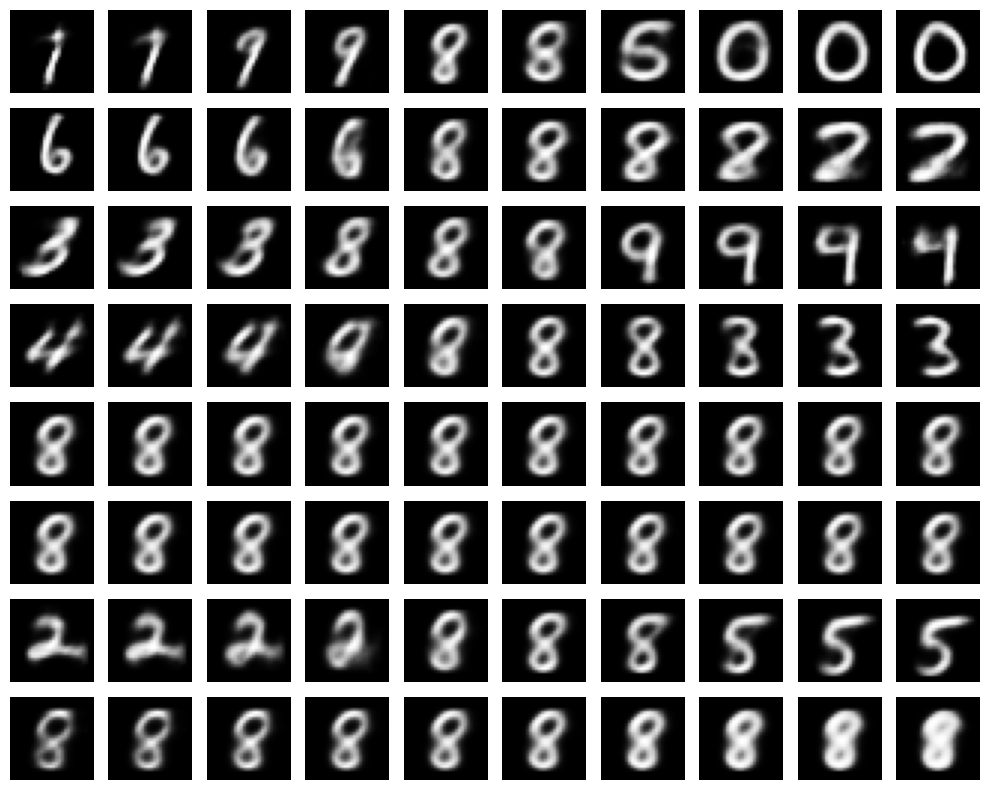

In [37]:
for beta in beta_values:
    best_model = beta_results[f'beta_{beta}']['model']
    print('beta: ' + str(beta))
    latent_traversal(model=best_model, n_steps=10, z_range=(-3, 3))
    

## Quick visual test for disentanglement:

If varying one latent dimension keeps the digit identity stable while modifying a single visual property (e.g., thickness, slant, or size), the representation is likely disentangled.

If varying one latent dimension changes the digit identity (e.g., 3 → 8 → 9), then the latent variable is entangled because it mixes several generative factors.

## Remarks: 

After exploring diffeernet values of β (1, 2, 3, 4 and 5), we  do not observe clearly disentangled latent factors in the latent traversals. But several patterns can be identified:

1. **Small β values (β = 1–2)**  
   The latent variables are highly active and produce large changes in the generated digits.  
   However, varying a single latent dimension often changes the **identity of the digit itself** (for example transitions such as 3 → 8 → 9 or 2 → 8 → 5).  
   This indicates strong **entanglement**, since multiple generative factors are controlled by the same latent variable.

2. **Intermediate β values (β = 3–4)**  
   Some traversals show smooth transitions between different digits (e.g. 6 → 8 → 2 or 0 → 8 → 7).  
   This suggests that the latent space captures meaningful directions in the digit manifold, but these directions still mix several visual factors together.

3. **Larger β values (β = 5)**  
   Many latent dimensions produce almost no change in the generated images.  
   In several rows the generated digit remains close to an "8" across the traversal, indicating that some latent variables have collapsed toward the prior and are no longer used by the decoder.

A consistent observation across many traversals is that the digit **8 frequently appears near the center of the latent traversal**. This likely corresponds to the decoder producing an "average" digit, since the shape of an 8 is relatively symmetric and shares structural features with many other MNIST digits.

Overall, these results highlight that **β-VAE encourages disentanglement but does not guarantee it**. In this experiment, the learned latent variables remain largely entangled, and increasing β mainly trades reconstruction quality for stronger regularization of the latent space.


## Advantages

* **Disentanglement**: By enforcing a stronger bottleneck, β-VAE encourages the model to separate distinct generative factors across different latent dimensions.

* **Interpretability**: Each latent variable often controls one intuitive aspect of the generated data, making the model more transparent and controllable.

* **Structure Discovery**: Useful in unsupervised learning scenarios to discover hidden explanatory variables.


##  Challenges

* **Reduced reconstruction quality**: A higher $\beta$ can hurt reconstruction performance, as the model sacrifices fidelity for regularization.

* **Tuning required**: The choice of $\beta$ is critical and problem-dependent. Too high a value can lead to **posterior collapse** or overly simplistic representations.


# GMM-VAE: Gaussian Mixture Prior for Disentangled Latent Representations

One of the limitations of standard VAEs is the use of a simple prior, typically a standard normal distribution $\mathcal{N}(0, I)$, which may not be expressive enough to capture the underlying multimodal structure of complex datasets. The **GMM-VAE** addresses this by replacing the prior with a **Gaussian Mixture Model (GMM)**, allowing for richer latent space modeling and often enabling clustering behavior in the latent space.

In this framework, the prior over the latent variable $z$ is defined as:

$$
p(z) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(z \mid \mu_k, \Sigma_k)
$$

where $\pi_k$ are mixture weights and each component $\mathcal{N}(z \mid \mu_k, \Sigma_k)$ is a Gaussian with its own mean and covariance.


## Variational Inference and the KL Term

The Evidence Lower Bound (ELBO) includes the KL divergence between the approximate posterior and the prior:


$$
\text{ELBO} = \mathbb{E}_{q(z \mid x)}[\log p(x \mid z)] - \mathrm{KL}(q(z \mid x) \| p(z))
$$

However, when the prior is a mixture of Gaussians, this KL term **cannot be computed in closed form in general**. There are two main strategies to address this:




### Case 1: Direct KL Between $q(z \mid x)$ and the GMM Prior

If we attempt to compute the KL divergence directly between a Gaussian approximate posterior and a GMM prior:

$$
\mathrm{KL}(q(z \mid x) \| p(z)) = \mathbb{E}_{q(z \mid x)} \left[ \log \frac{q(z \mid x)}{\sum_k \pi_k \, \mathcal{N}(z \mid \mu_k, \Sigma_k)} \right]
$$

this expression involves a **logarithm of a sum of Gaussians**, which **does not have an analytical solution**. In this case, we resort to:

* **Monte Carlo approximation** of the KL via sampling from $q(z \mid x)$.
* Or **upper-bound techniques**, such as importance weighting or variational bounds.

While feasible, these methods can be less stable and slower than the structured approach using the latent variable $c$.



### Case 2: Introducing a Discrete Latent Variable $c$ (GMM-VAE)

A common way to make a Gaussian Mixture prior tractable in a Variational Autoencoder is to introduce an explicit **discrete latent variable**  
$c \in \{1, \dots, K\}$ indicating which component of the mixture a sample belongs to.

The generative model is defined as:
$$
p(c) = \mathrm{Cat}(c; \boldsymbol{\pi}), \qquad
p(z \mid c = k) = \mathcal{N}(z \mid \mu_k, \Sigma_k),
$$
which leads to the joint prior:
$$
p(z, c) = p(c)\, p(z \mid c).
$$


### Variational Approximation

We now need to define a joint variational distribution $q(z, c \mid x)$.  
A natural starting point would be to write:
$$
q(z, c \mid x) = q_\phi(z \mid x)\, q(c \mid x, z).
$$

In principle, one could further simplify this as:
$$
q(z, c \mid x) = q_\phi(z \mid x)\, q(c \mid x),
$$
by assuming that the discrete variable $c$ depends only on the input $x$.
However, modeling $q(c \mid x)$ directly in pixel space is often difficult and unstable.

Instead, we adopt a more practical factorization and approximate the variational posterior as:
$$
q(z, c \mid x) = q_\phi(z \mid x)\, q_\psi(c \mid \tilde z),
$$
where $\tilde z$ is a representation derived from the encoder output.


In our implementation, the continuous latent variable is inferred using a standard Gaussian encoder, as in the vanilla VAE:
$$
q_\phi(z \mid x) = \mathcal{N}\!\left(z \mid \mu_\phi(x), \mathrm{diag}\big(\sigma_\phi^2(x)\big)\right).
$$

Additionally, we introduce a new auxiliary network to predict **soft responsibilities** over the mixture components, i.e., to model:
$$
q_\psi(c \mid \tilde z).
$$

Rather than using a noisy sample $z \sim q_\phi(z \mid x)$, we choose a **deterministic summary** of the encoder output:
$$
\tilde z = \mu_\phi(x).
$$

This design choice avoids the additional variance introduced by stochastic sampling and leads to a more stable and reliable optimization in practice.



### KL Decomposition

With this factorization, the KL divergence between the variational posterior and the mixture prior decomposes as:
$$
\mathrm{KL}\!\left(q(z, c \mid x)\,\|\,p(z, c)\right)
=
\mathbb{E}_{q_\psi(c \mid \tilde z)}\!\left[
\mathrm{KL}\!\left(q_\phi(z \mid x)\,\|\,p(z \mid c)\right)
\right]
+
\mathrm{KL}\!\left(q_\psi(c \mid \tilde z)\,\|\,p(c)\right).
$$

#### 1. Expected KL over the Gaussian components

Since both $q_\phi(z \mid x)$ and $p(z \mid c=k)$ are Gaussian distributions, the KL divergence
$$
\mathrm{KL}\!\left(q_\phi(z \mid x)\,\|\,p(z \mid c=k)\right)
$$
has a **closed-form expression**.

The expectation over $c$ is computed **exactly** as a weighted sum:
$$
\mathbb{E}_{q_\psi(c \mid \tilde z)}[\cdot]
=
\sum_{k=1}^{K} q_k \,
\mathrm{KL}\!\left(q_\phi(z \mid x)\,\|\,p(z \mid c=k)\right),
$$
where $q_k = q_\psi(c = k \mid \tilde z)$.

#### 2. KL between categorical distributions

The second term is the KL divergence between two categorical distributions:
$$
\mathrm{KL}\!\left(q(c \mid \tilde z)\,\|\,p(c)\right)
=
\sum_{k=1}^{K} q_k \big( \log q_k - \log p_k \big),
$$
where:
- $q_k = q_\psi(c = k \mid \tilde z)$,
- $p_k = \pi_k$ are the mixture weights.

In practice, this term is computed using `log_softmax`, which ensures numerical stability.  


### Final Objective

The Evidence Lower Bound (ELBO) optimized by the model is:
$$
\mathcal{L}
=
\mathbb{E}_{q_\phi(z \mid x)}\!\left[\log p_\theta(x \mid z)\right]
-
\beta \left(
\mathbb{E}_{q_\psi(c \mid \tilde z)}\!\left[
\mathrm{KL}\!\left(q_\phi(z \mid x)\,\|\,p(z \mid c)\right)
\right]
+
\mathrm{KL}\!\left(q_\psi(c \mid \tilde z)\,\|\,p(c)\right)
\right),
$$
where $\beta \geq 1$ controls the strength of the regularization (if we include the $\beta$-VAE formulation).

This formulation yields a **fully tractable GMM-VAE**, enabling multimodal latent representations and clustering behavior while retaining the standard VAE training procedure.


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_11.png" width=90%>

### GMM-VAE Implementation
Next, we will implement the GMM-VAE following the first approach. Compared to the standard VAE, there are a few important modifications to introduce:

* The prior is no longer a fixed standard Gaussian. Instead, we define a **Gaussian mixture prior** consisting of a categorical distribution $p(c)$ over $K$ components, together with a Gaussian $p(z \mid c)$ for each component. The parameters of all these distributions are learned during training.
* We need to add a new network that models the **categorical encoder** $q(c \mid \tilde z)$, which assigns probabilities to each mixture component given the latent variable (we consider its mean for stability).
* Another key difference is that the **ELBO computation** now changes due to the new prior. Specifically, since the prior is a Gaussian mixture instead of a single Gaussian, the KL divergence term must be adapted accordingly. As we discussed before, this results in two contributions: one from the KL between Gaussians and another from the KL between categorical distributions. Importantly, both terms admit **closed-form solutions**, so the ELBO remains tractable and can be computed analytically during training.

In [38]:
class GMM_Prior(nn.Module):
    def __init__(self, M, K):
        super(GMM_Prior, self).__init__()
        self.M = M
        self.K = K
        # Define parameters of the K gaussians
        self.mu = nn.Parameter(torch.randn(K, M))
        self.log_var = nn.Parameter(torch.zeros(K, M))
        # Define parameters of the categorical distribution
        self.logits = nn.Parameter(torch.zeros(K))  # log(pi_k)

    def sample(self, batch_size):
        pi = F.softmax(self.logits, dim=0)  # pi_k = exp(logit_k) and we use softmax to ensure sum_k (pi_k) =1
        # Sample from p(c)
        c = torch.multinomial(pi, batch_size, replacement=True)  # (B,)
        # Sample from p(z|c)
        mu = self.mu[c]
        std = torch.exp(0.5 * self.log_var[c])
        z = mu + std * torch.randn_like(mu)  #(B, M)
        return z, c


In [39]:
import torch.nn.functional as F
import torch.nn as nn
import torch

class GMMVAE(nn.Module):
    def __init__(self, encoder_net, decoder_net, M=16, K=10, beta=1.0):
        super(GMMVAE, self).__init__()
        self.encoder = Encoder(encoder_net=encoder_net)
        self.decoder = BernoulliDecoder(decoder_net=decoder_net)
        self.prior = GMM_Prior(M=M, K=K)
        self.K = K
        self.beta = beta

        # New network to compute q(c|mu_e)
        self.q_c_net = nn.Sequential(
            nn.Linear(M, 64),
            nn.ReLU(),
            nn.Linear(64, K)
        )

    def forward(self, x, return_components=False):
        # Generate latent variable with encoder
        mu_e, log_var_e = self.encoder.encode(x)
        z = self.encoder.sample(mu_e=mu_e, log_var_e=log_var_e)
        # Prefer deterministic input for stability: q(c | mu_e)
        q_c_logits = self.q_c_net(mu_e)
        log_q_c = F.log_softmax(q_c_logits, dim=1)  # (B, K)
        q_c = log_q_c.exp()

        RE = self.decoder.log_prob(x, z)  # Reconstruction error (log-likelihood)

        # Prepare prior params per component
        mu_p = self.prior.mu.unsqueeze(0)  # (1, K, M)
        log_var_p = self.prior.log_var.unsqueeze(0)  # (1, K, M)
        var_p = torch.exp(log_var_p)

        # Posterior params
        mu_e = mu_e.unsqueeze(1)  # (B, 1, M)
        log_var_e = log_var_e.unsqueeze(1) # (B, 1, M)
        var_e = torch.exp(log_var_e)

        # KL divergence for z: KL[q(z|x) || p(z|c)]
        # KL_z,k = KL( N(mu_q, var_q) || N(mu_p[k], var_p[k]) ), closed form
        kl_z = 0.5 * (log_var_p - log_var_e + (var_e + (mu_e - mu_p)**2) / var_p - 1).sum(-1)  # (B, K)
        # E_{q(c|·)}[KL_z, k] = sum_k q_k * kl_zk
        KL_z = (q_c * kl_z).sum(dim=1) # (B,)

        # KL divergence for c: KL_c = KL(q(c|mu_e) || p(c))
        log_p_c = F.log_softmax(self.prior.logits, dim=0).unsqueeze(0) # (1, K)
        KL_c = (q_c * (log_q_c - log_p_c)).sum(dim=1) # (B,)

        # ELBO with beta weight on KL terms
        elbo = RE - self.beta * (KL_z + KL_c)

        loss = -elbo.sum()  # negative ELBO (to minimize)

        if return_components:
            return loss, RE.sum(), (KL_z + KL_c).sum()
        else:
            return loss

    def sample(self, batch_size=64):
        z, _ = self.prior.sample(batch_size)
        return self.decoder.sample(z)


Epoch: 0, val nll=154.7953108642578, RE=-143.40173203125, KL=11.393578028869628
Epoch: 1, val nll=131.09077236328125, RE=-116.22749482421875, KL=14.863276586914063
Epoch: 2, val nll=123.21039426269532, RE=-107.76108659667969, KL=15.449307238769531
Epoch: 3, val nll=118.58991651611328, RE=-101.8536539794922, KL=16.736261376953124
Epoch: 4, val nll=115.59119289550782, RE=-98.70711663818359, KL=16.884076458740235
Epoch: 5, val nll=113.50125391845702, RE=-96.25485559082031, KL=17.246399740600587
Epoch: 6, val nll=111.87903698730469, RE=-93.76419514160156, KL=18.114841677856447
Epoch: 7, val nll=110.394830859375, RE=-91.83155692138672, KL=18.563274197387695
Epoch: 8, val nll=109.81710104980469, RE=-90.93129155273438, KL=18.88581134338379
Epoch: 9, val nll=109.31914382324219, RE=-90.83660500488281, KL=18.482538122558594
Epoch: 10, val nll=108.4540763671875, RE=-89.48852930908203, KL=18.96554790649414
Epoch: 11, val nll=107.90424389648437, RE=-88.94800441894532, KL=18.95623889160156
Epoch: 12

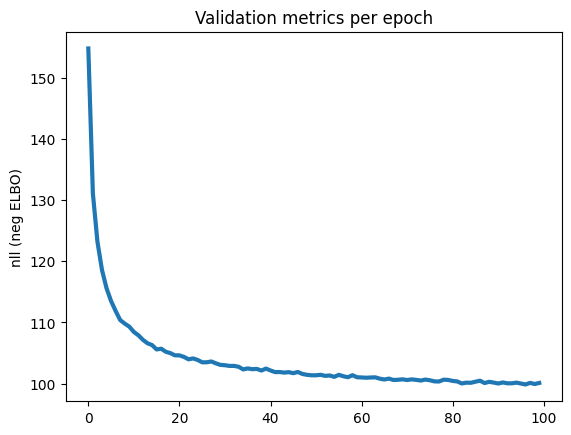

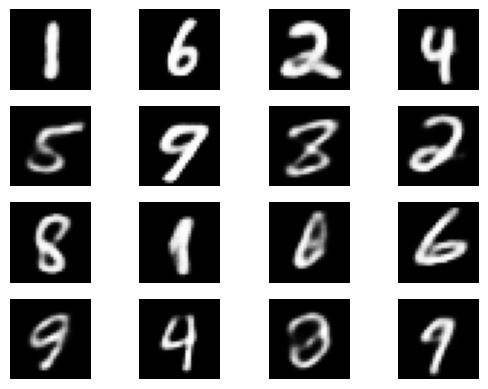

In [40]:
M = 16              # Latent dimension
K = 12              # Number of mixture components
max_patience = 20
beta = 1.0

# Define your encoder and decoder networks
GMM_encoder = nn.Sequential(nn.Linear(D, hidden_layer_neurons), nn.LeakyReLU(),
                        nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
                        nn.Linear(hidden_layer_neurons, 2 * M))

GMM_decoder = nn.Sequential(nn.Linear(M, hidden_layer_neurons), nn.LeakyReLU(),
                        nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
                        nn.Linear(hidden_layer_neurons, D))

# Instantiate model
model_GMM = GMMVAE(encoder_net=GMM_encoder, decoder_net=GMM_decoder, beta= beta, M=M, K=K)


optimizer_GMM = torch.optim.Adam([p for p in model_GMM.parameters() if p.requires_grad], lr=1e-3)

nll_val, _, _, best_model_GMM = training(
    max_patience=max_patience,
    num_epochs=num_epochs,
    model=model_GMM,
    optimizer=optimizer_GMM,
    training_loader=training_loader,
    val_loader=val_loader, plot=False
)

# Plot nll_val
epochs = np.arange(len(nll_val))
plt.figure()
epochs = np.arange(len(nll_val))
plt.plot(epochs, nll_val, linewidth=3, color='C0')
plt.ylabel('nll (neg ELBO)')
plt.title('Validation metrics per epoch')


test_loss, _, _ = evaluation(test_loader=test_loader, model_best=best_model_GMM)
print(f"Test ELBO loss: {test_loss:.2f}")

samples_generated(best_model_GMM)

In [41]:
from torchvision import datasets, transforms
from torch.utils.data import Dataset

class MNIST_label(Dataset):
    def __init__(self, mode='train', transforms=None):
        if mode == 'train':
            self.data = datasets.MNIST(root='.', train=True, download=True, transform=transforms)
        else: # Using test split for evaluation
            self.data = datasets.MNIST(root='.', train=False, download=True, transform=transforms)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, label = self.data[idx]
        # Flatten the 28x28 image to a 784-dimensional vector
        return img.view(-1), label

# Define transformations
mnist_transforms = transforms.Compose([
    transforms.ToTensor(),
])

# Create instances of the new dataset
train_dataset_labels = MNIST_label(mode='train', transforms=mnist_transforms)
training_loader_labels = DataLoader(train_dataset_labels, batch_size=batch_size, shuffle=True)

In [42]:
from sklearn.manifold import TSNE

def plot_latent_tsne_with_labels(model, data_loader, n_samples=1000):
    """
    Projects the latent space of a VAE/GMM-VAE model using t-SNE and displays the true digit labels.

    Args:
        model: trained VAE or GMM-VAE model
        data_loader: DataLoader providing the input data
        n_samples: maximum number of samples to use for t-SNE
    """

    model.eval()
    zs = []
    labels = []
    for x, y in data_loader:
        x = x.to(next(model.parameters()).device)
        with torch.no_grad():
            mu_e, log_var_e = model.encoder.encode(x)
            z = model.encoder.sample(mu_e=mu_e, log_var_e=log_var_e)
        zs.append(z.cpu())
        labels.append(y)
        if len(torch.cat(zs)) >= n_samples:
            break
    zs = torch.cat(zs, dim=0)[:n_samples]  # (N, latent_dim)
    labels = torch.cat(labels, dim=0)[:n_samples]  # (N,)
    zs_np = zs.numpy()
    labels_np = labels.numpy()

    # t-SNE projection
    z_2d = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(zs_np)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(z_2d[:, 0], z_2d[:, 1], c=labels_np, cmap='tab10', s=10, alpha=0.7)
    plt.title('Latent space projected with t-SNE + True Labels')
    plt.xlabel('t-SNE dim 1')
    plt.ylabel('t-SNE dim 2')
    plt.colorbar(scatter, ticks=range(10), label="Digit Label")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

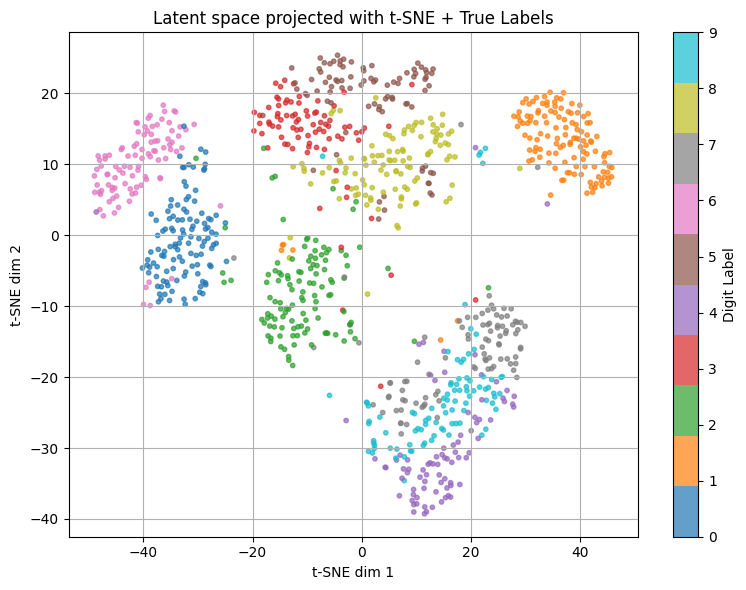

In [43]:
# Plot latent space of GMMVAE with true labels
plot_latent_tsne_with_labels(best_model_GMM, training_loader_labels, n_samples=1000)

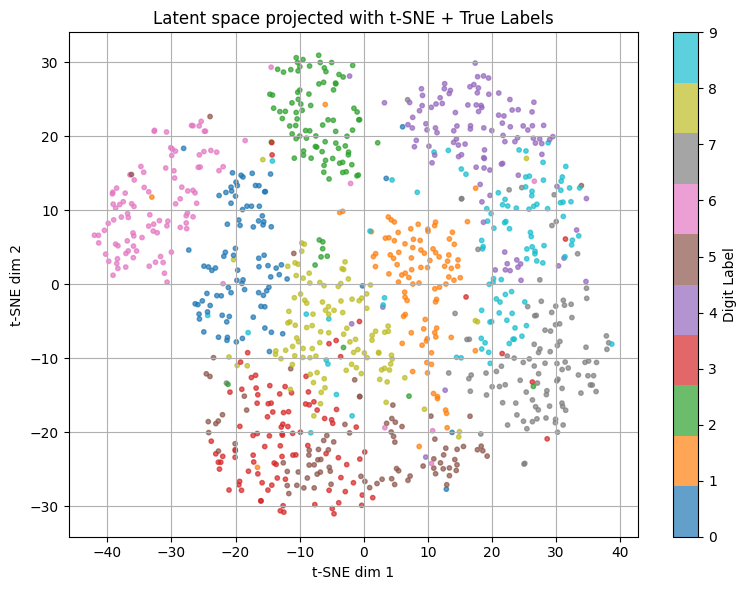

In [44]:
# Plot latent space of BetaVAE with true labels
beta = 2.0
best_model = beta_results[f'beta_{beta}']['model']
plot_latent_tsne_with_labels(best_model, training_loader_labels, n_samples=1000)

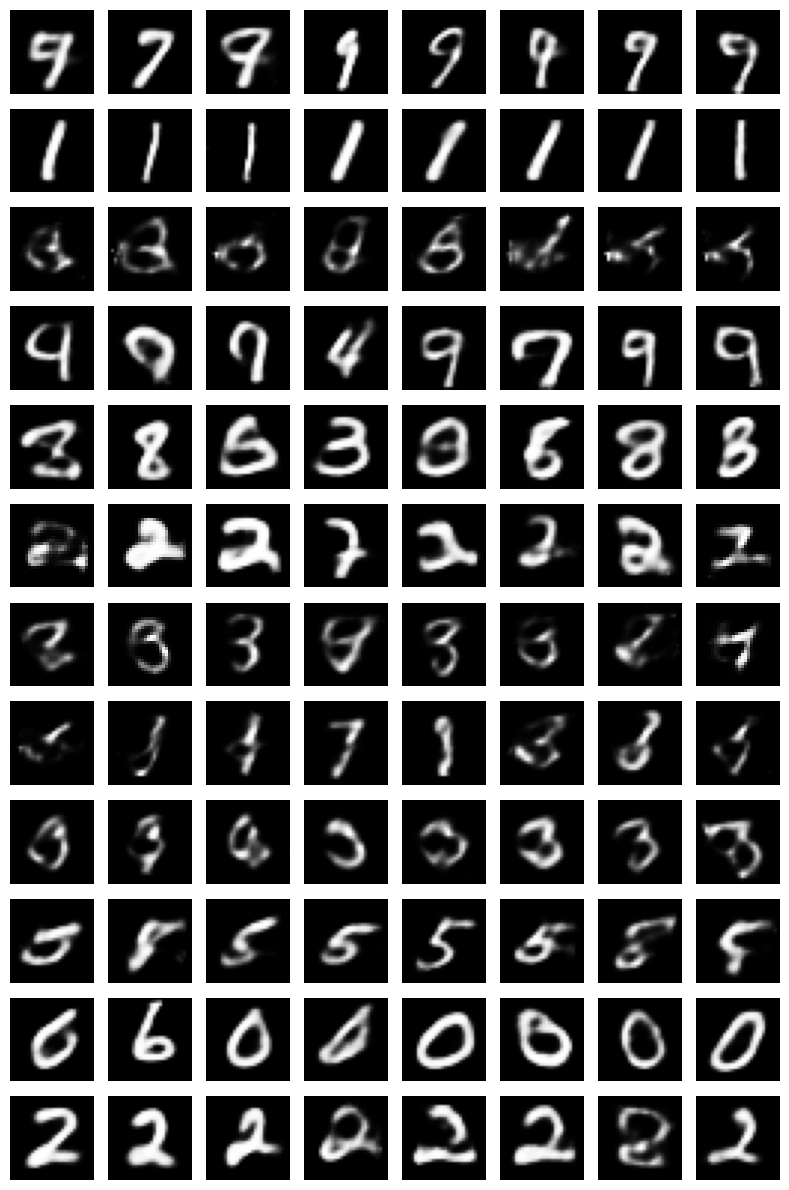

In [45]:
import torch
import matplotlib.pyplot as plt

def sample_each_gmm_component(model_GMM, n_samples_per_component=8):
    model_GMM.eval()
    K = model_GMM.prior.K
    M = model_GMM.prior.M

    fig, axes = plt.subplots(K, n_samples_per_component, figsize=(n_samples_per_component, K))
    for k in range(K):
        mu_k = model_GMM.prior.mu[k].detach()
        std_k = torch.exp(0.5 * model_GMM.prior.log_var[k]).detach()
        for i in range(n_samples_per_component):
            z = mu_k + std_k * torch.randn(M)
            #z = mu_k + std_k * torch.zeros(M)
            z = z.unsqueeze(0)
            with torch.no_grad():
                x_hat = model_GMM.decoder.sample(z)
            img = x_hat.cpu().numpy().reshape(28, 28)
            ax = axes[k, i] if K > 1 else axes[i]
            ax.imshow(img, cmap='gray')
            ax.axis('off')
        axes[k, 0].set_ylabel(f'Comp {k}', fontsize=8)
    plt.tight_layout()
    plt.show()


sample_each_gmm_component(model_GMM)

##  Limitations of the GMM-VAE

While the **GMM-VAE** improves over the standard VAE by introducing a multimodal prior, it still has several limitations:

* **Continuous latent variables**: Although the mixture components encourage clustering, the latent variables remain continuous. This can make it harder to learn sharp boundaries between clusters.
* **Posterior collapse**: If the categorical variable $c$ is not well-utilized, the model may ignore it and reduce to something close to a standard VAE.
* **Mode overlap**: Different Gaussian components may overlap heavily in latent space, reducing interpretability of the clusters.
* **Training instability**: Optimizing both continuous and discrete variables together can be challenging, especially as $K$ increases.

These issues motivate the exploration of **discrete latent representations**, where the model commits to a finite set of latent codes rather than relying on continuous Gaussians.


#  Vector-Quantized VAE (VQ-VAE)

The **VQ-VAE** introduces a fundamentally different idea: instead of sampling continuous latent variables, the encoder maps inputs to the nearest element in a **discrete codebook** of embeddings.

* The **codebook** is a set of $K$ learnable vectors $\{{\bf e}_k\}_{k=1}^K$.
* For each input $x$, the encoder outputs a continuous embedding ${\bf z}_e({\bf x})$, which is then **quantized** to the closest code ${\bf e}^*$.
* The decoder reconstructs the input from this discrete code.

Note: Here, **quantization** means replacing the continuous embedding ${\bf z}_e({\bf x})$ with the nearest vector from the finite set of codebook entries. The index $k^*$ that identifies the chosen code is discrete ($k^* \in \{1,…,K\}$), but the codebook vectors $\{{\bf e}_k\}_{k=1}^K$ themselves are continuous and trainable. This is why we say that the latent space is discrete since, although the decoder input is a continuous vector  ${\bf e}_k$​, it must be selected from a finite collection of possibilities.

### Training objective

The VQ-VAE replaces the standard KL term of a VAE with two new terms related to the **codebook**. Let ${\bf z}_e({\bf x})$ be the encoder output and  ${\bf e}^*$ the closest codebook vector. The loss for a single data point $\bf x$ is:

$$
\mathcal{L}_\text{VQ-VAE}({\bf x}) =
\underbrace{\mathbb{E}_{q({\bf z}|{\bf x})}[\log p({\bf x}|{\bf z})]}_{\text{reconstruction loss}}
+ \underbrace{\| \text{sg}[{\bf z}_e({\bf x})] - {\bf e}^* \|^2}_{\text{codebook loss}}
+ \underbrace{\beta \, \| {\bf z}_e({\bf x}) - \text{sg}[{\bf e}^*] \|^2}_{\text{commitment loss}}
$$

where:

* $\text{sg}[\cdot]$ is the stop-gradient operator (gradients do not flow through this argument).
* $\beta$ is a hyperparameter controlling how strongly the encoder commits to the chosen code.

Now, we have three different terms:
- **Reconstruction loss**: same as in VAE, measures how well the decoder reconstructs the input from the quantized latent.
- **Codebook loss**: moves the nearest embedding towards the encoder output.
- **Commitment loss**: encourages the encoder output (embedding) to stay close to the selected code, preventing codebook collapse or unstable training.

Note that this formulation **eliminates the KL term** entirely, replacing the probabilistic latent modeling with a discrete, learnable codebook.


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_12.png" width=90%>

### VQ-VAE Implementation

When moving from the GMM-VAE to the VQ-VAE implementation, we have to include the following modifications:

1. **No Gaussian mixture prior**

   * In the VQ-VAE there is no Gaussian mixture, so the parameters $K$ (number of mixture components) and $\beta$ (KL weight) are removed.
   * Instead, we define:

     * `embedding_dim`: the dimensionality of the code vectors (equivalent to $M$ in the VAE/GMM-VAE).
     * `num_embeddings`: the number of discrete codes in the codebook (replaces $K$).

2. **Encoder output**

   * In the GMM-VAE, the encoder outputs are the parameters of a Gaussian (mean and std), so the output is of size $2M$.
   * In the VQ-VAE, the encoder only outputs a latent vector of size `embedding_dim`.

3. **Latent representation**

   * In the GMM-VAE, ${\bf z}$ is sampled from a Mixture of Gaussians.
   * In the VQ-VAE,  stochastic sampling from Gaussians disappears, since the latent representation is now a deterministic lookup in the codebook. That is, ${\bf z}$ is replaced by the nearest embedding vector from the learned codebook ${\bf e}^*$.

4. **Straight-through estimator**

   In the VQ-VAE, the encoder output ${\bf z}_e({\bf x})$​ is mapped to the nearest codebook vector ${\bf e}^*$​, which is a discrete operation and thus non-differentiable. To train the encoder despite this, the model uses the straight-through gradient estimator: during the forward pass, the decoder receives the quantized vector ${\bf e}^*$​, but during the backward pass, gradients are propagated as if the decoder had received the continuous embedding ${\bf z}_e({\bf x})$​. This trick allows gradients to flow into the encoder parameters even though quantization is discrete.

4. **ELBO vs VQ Loss**

   * The GMM-VAE optimizes the ELBO = Reconstruction − KL.
   * The VQ-VAE optimizes Reconstruction + Vector Quantization Loss + Commitment Loss.
   * Therefore, the training loop remains structurally similar, but the loss function inside the model changes.


In [46]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class Encoder(nn.Module):
    def __init__(self, encoder_net):
        super(Encoder, self).__init__()
        self.encoder = encoder_net

    def encode(self, x):
        # Instead of (mu, logvar), we output a continuous embedding z_e(x)
        z_e = self.encoder(x)
        return z_e



class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost=0.25):
        super(VectorQuantizer, self).__init__()
        self.embedding_dim = embedding_dim
        self.num_embeddings = num_embeddings
        self.commitment_cost = commitment_cost

        # Codebook (K x D)
        self.embeddings = nn.Embedding(num_embeddings, embedding_dim)
        # Initialize sampling from a uniform distribution
        self.embeddings.weight.data.uniform_(-1/self.num_embeddings, 1/self.num_embeddings)

    def forward(self, z_e):
        # Flatten input to efficient distance computation
        flat_z = z_e.view(-1, self.embedding_dim)  #(B ·D, embedding_dim) or (B · H · W, embedding_dim)

        # Compute distances to codebook embeddings
        distances = (flat_z.pow(2).sum(1, keepdim=True)
                     - 2 * flat_z @ self.embeddings.weight.t()
                     + self.embeddings.weight.pow(2).sum(1))

        # Get nearest embedding index
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)
        encodings = torch.zeros(encoding_indices.size(0), self.num_embeddings, device=z_e.device)
        encodings.scatter_(1, encoding_indices, 1) # We create a one-hot encoding

        # Quantized vectors
        z_q = encodings @ self.embeddings.weight # This product gives us the quantized vectors (the nearest embedding)
        z_q = z_q.view(z_e.shape)

        # Loss terms: to stop the gradients we detach the corresponding vectors
        commitment_loss = self.commitment_cost * F.mse_loss(z_e.detach(), z_q)
        codebook_loss = F.mse_loss(z_e, z_q.detach())

        # Straight-through estimator
        z_q_st = z_e + (z_q - z_e).detach()
        # In the forward pass, we use the quantized vector zq​ (e*) -> z_q_st = z_e + (z_q - z_e) = z_q
        # In the backward pass (detach variables does not pass gradients) -> z_q_st = ze,
        # this way, ze​ goes through the decoder, so that gradients can be sent back to the encoder.

        return z_q_st, commitment_loss + codebook_loss


class VQVAE(nn.Module):
    def __init__(self, encoder_net, decoder_net, embedding_dim=16, num_embeddings=64, commitment_cost=0.25):
        super(VQVAE, self).__init__()
        self.encoder = Encoder(encoder_net=encoder_net)
        self.decoder = BernoulliDecoder(decoder_net=decoder_net)
        self.vq = VectorQuantizer(num_embeddings=num_embeddings,
                                  embedding_dim=embedding_dim,
                                  commitment_cost=commitment_cost)

    def forward(self, x):
        # Encode input
        z_e = self.encoder.encode(x)

        # Quantize
        z_q, vq_loss = self.vq(z_e)

        # Reconstruction log prob
        RE = self.decoder.log_prob(x, z_q)

        # VQ-VAE loss (negative ELBO analogue)
        loss = -(RE).sum() + vq_loss * x.size(0)  # scale vq_loss per batch

        return loss

    def sample(self, batch_size=64):
        # Sample discrete codes uniformly
        idx = torch.randint(0, self.vq.num_embeddings, (batch_size,))
        z_q = self.vq.embeddings(idx)
        return self.decoder.sample(z_q)


Epoch: 0, val nll=553.1204342773437, RE=0.0, KL=0.0
Epoch: 1, val nll=387.7181120605469, RE=0.0, KL=0.0
Epoch: 2, val nll=389.5522099121094, RE=0.0, KL=0.0
Epoch: 3, val nll=282.0003942382813, RE=0.0, KL=0.0
Epoch: 4, val nll=314.8555361328125, RE=0.0, KL=0.0
Epoch: 5, val nll=320.80741884765627, RE=0.0, KL=0.0
Epoch: 6, val nll=282.6167237304688, RE=0.0, KL=0.0
Epoch: 7, val nll=247.5165736328125, RE=0.0, KL=0.0
Epoch: 8, val nll=237.86337397460937, RE=0.0, KL=0.0
Epoch: 9, val nll=231.522871484375, RE=0.0, KL=0.0
Epoch: 10, val nll=221.10308876953124, RE=0.0, KL=0.0
Epoch: 11, val nll=210.16683408203124, RE=0.0, KL=0.0
Epoch: 12, val nll=202.43642687988282, RE=0.0, KL=0.0
Epoch: 13, val nll=203.09329853515624, RE=0.0, KL=0.0
Epoch: 14, val nll=201.76447185058595, RE=0.0, KL=0.0
Epoch: 15, val nll=202.33942670898438, RE=0.0, KL=0.0
Epoch: 16, val nll=194.8387046875, RE=0.0, KL=0.0
Epoch: 17, val nll=185.99882019042968, RE=0.0, KL=0.0
Epoch: 18, val nll=187.03128125, RE=0.0, KL=0.0
Epo

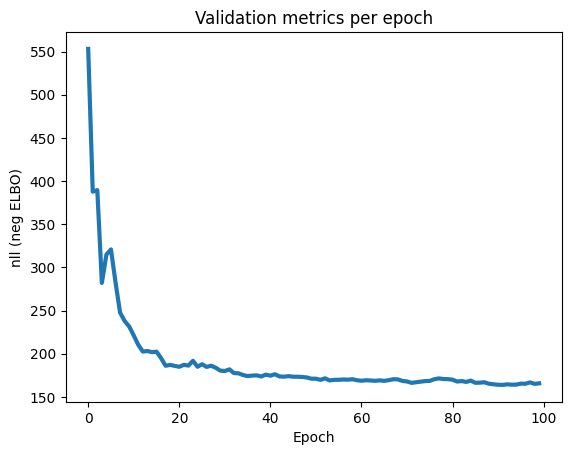

FINAL LOSS: nll=165.6313772705078
Test VQ-VAE loss: 165.63


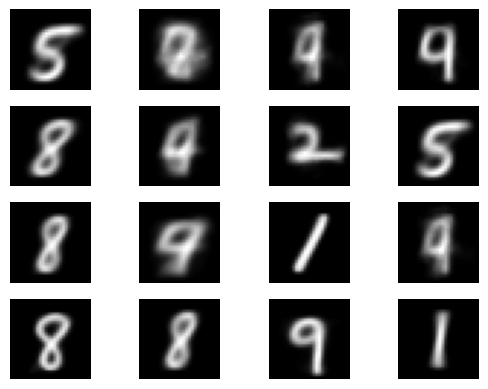

In [47]:
# Model parameter
embedding_dim = 16     # Embedding dimension (M)
num_embeddings = 64    # Number of vectors in the codebook
max_patience = 20

# Encoder and decoder definition
VQ_encoder = nn.Sequential(
    nn.Linear(D, hidden_layer_neurons), nn.LeakyReLU(),
    nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
    nn.Linear(hidden_layer_neurons, embedding_dim)   # <--- ya no 2*M, solo emb_dim
)

VQ_decoder = nn.Sequential(
    nn.Linear(embedding_dim, hidden_layer_neurons), nn.LeakyReLU(),
    nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
    nn.Linear(hidden_layer_neurons, D)
)

# Define VQ-VAE model
model_VQ = VQVAE(encoder_net=VQ_encoder, decoder_net=VQ_decoder, embedding_dim=embedding_dim,
    num_embeddings=num_embeddings, commitment_cost=0.25)

# Optimizer
optimizer_VQ = torch.optim.Adam([p for p in model_VQ.parameters() if p.requires_grad], lr=1e-3)

# Training
nll_val,_,_, best_model_VQ = training(max_patience=max_patience, num_epochs=num_epochs,
    model=model_VQ, optimizer=optimizer_VQ, training_loader=training_loader, val_loader=val_loader, plot=False)


# Plot nll_val
epochs = np.arange(len(nll_val))
plt.figure()
epochs = np.arange(len(nll_val))
plt.plot(epochs, nll_val, linewidth=3, color='C0')
plt.ylabel('nll (neg ELBO)')
plt.title('Validation metrics per epoch')
plt.xlabel('Epoch')
plt.show()

# Evaluation
test_loss, _, _ = evaluation(test_loader=test_loader, model_best=best_model_VQ)
print(f"Test VQ-VAE loss: {test_loss:.2f}")

# Generate samples
samples_generated(best_model_VQ)

Compared to the GMM-VAE, the VQ-VAE produces sharper and more faithful reconstructions. The discrete codebook enforces a more structured latent representation, reducing blur and helping preserve fine details.

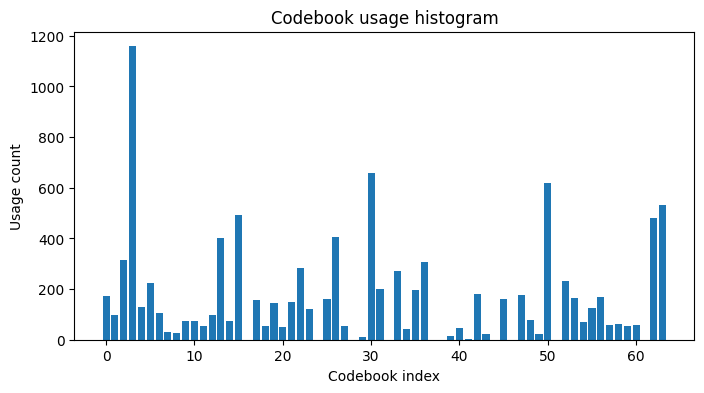

Unused codebook elements: 10 of 64


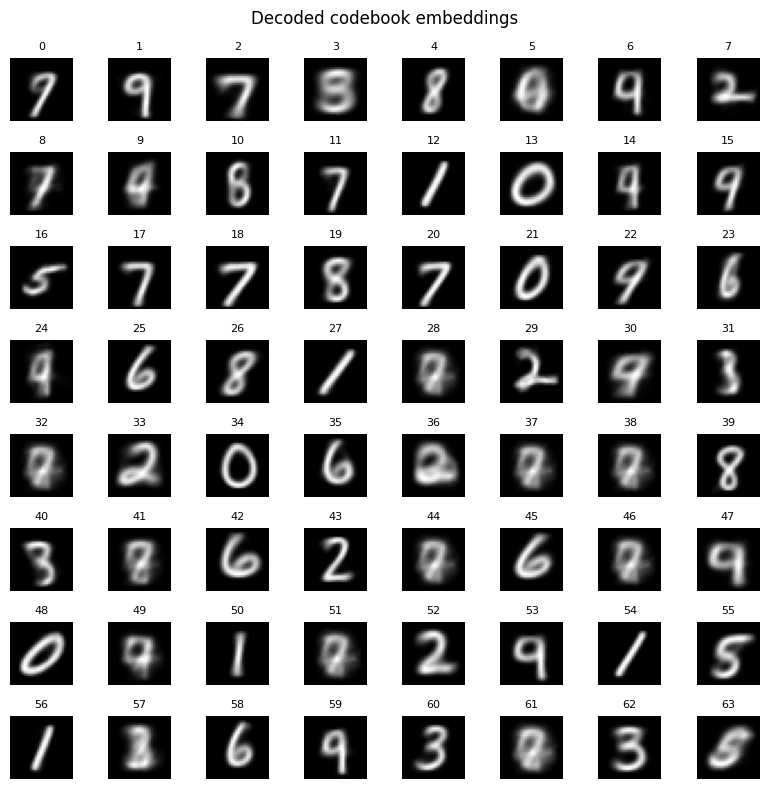

In [48]:
import torch
import numpy as np

import matplotlib.pyplot as plt

def analyze_codebook_usage(model_VQ, data_loader, n_samples=10000):
    """
    Analyze the use of the codebook in a VQ-VAE model.
        - Visualize the usage frequency of each code.
        - Show whether there are unused codes (codebook collapse).
        - Decode and visualize each embedding from the codebook as an image.
    """
    model_VQ.eval()
    device = next(model_VQ.parameters()).device
    embedding_dim = model_VQ.vq.embedding_dim
    num_embeddings = model_VQ.vq.num_embeddings

    # 1. Collect the indices of the codes used in the dataset
    code_counts = np.zeros(num_embeddings, dtype=int)
    total = 0
    with torch.no_grad():
        for batch in data_loader:
            if isinstance(batch, (list, tuple)):
                x = batch[0]
            else:
                x = batch
            x = x.to(device)
            z_e = model_VQ.encoder.encode(x)
            flat_z = z_e.view(-1, embedding_dim)
            distances = (flat_z.pow(2).sum(1, keepdim=True)
                         - 2 * flat_z @ model_VQ.vq.embeddings.weight.t()
                         + model_VQ.vq.embeddings.weight.pow(2).sum(1))
            encoding_indices = torch.argmin(distances, dim=1)
            inds_np = encoding_indices.cpu().numpy()
            for idx in inds_np:
                code_counts[idx] += 1
            total += len(inds_np)
            if total >= n_samples:
                break

    # 2. Visualize the histogram of code usage
    plt.figure(figsize=(8, 4))
    plt.bar(np.arange(num_embeddings), code_counts)
    plt.xlabel("Codebook index")
    plt.ylabel("Usage count")
    plt.title("Codebook usage histogram")
    plt.show()

    # 3. Show how many codes are not used
    unused = np.sum(code_counts == 0)
    print(f"Unused codebook elements: {unused} of {num_embeddings}")

    # 4. Visualize the decoded embeddings as images
    with torch.no_grad():
        embeddings = model_VQ.vq.embeddings.weight.data.to(device)
        decoded_imgs = model_VQ.decoder.sample(embeddings).cpu().numpy()

    n_cols = 8
    n_rows = int(np.ceil(num_embeddings / n_cols))
    plt.figure(figsize=(n_cols, n_rows))
    for i in range(num_embeddings):
        plt.subplot(n_rows, n_cols, i + 1)
        plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
        plt.axis('off')
        plt.title(str(i), fontsize=8)
    plt.suptitle("Decoded codebook embeddings")
    plt.tight_layout()
    plt.show()

analyze_codebook_usage(best_model_VQ, training_loader)

In [49]:
import torch
import numpy as np

import matplotlib.pyplot as plt

def sample_codebook_images(model_VQ, n_samples=16, use_learned_dist=False):
    """
    Genera imágenes muestreadas del codebook de un VQ-VAE.
    - use_learned_dist=False: selecciona códigos uniformemente al azar.
    - use_learned_dist=True: selecciona códigos según la frecuencia observada en el dataset.
    """
    model_VQ.eval()
    device = next(model_VQ.parameters()).device
    num_embeddings = model_VQ.vq.num_embeddings
    embedding_dim = model_VQ.vq.embedding_dim

    if use_learned_dist:
        # Compute the empirical distribution of code usage
        code_counts = np.zeros(num_embeddings, dtype=int)
        total = 0
        with torch.no_grad():
            for batch in training_loader:
                if isinstance(batch, (list, tuple)):
                    x = batch[0]
                else:
                    x = batch
                x = x.to(device)
                z_e = model_VQ.encoder.encode(x)
                flat_z = z_e.view(-1, embedding_dim)
                distances = (flat_z.pow(2).sum(1, keepdim=True)
                             - 2 * flat_z @ model_VQ.vq.embeddings.weight.t()
                             + model_VQ.vq.embeddings.weight.pow(2).sum(1))
                encoding_indices = torch.argmin(distances, dim=1)
                inds_np = encoding_indices.cpu().numpy()
                for idx in inds_np:
                    code_counts[idx] += 1
                total += len(inds_np)
                if total >= 10000:
                    break
        probs = code_counts / code_counts.sum()
        # Avoid issues if any code is not used.
        if np.any(probs == 0):
            probs = probs + 1e-8
            probs = probs / probs.sum()
        sampled_indices = np.random.choice(num_embeddings, size=n_samples, replace=True, p=probs)
    else:
        # Uniform selection
        sampled_indices = np.random.choice(num_embeddings, size=n_samples, replace=True)

    # Retrieve the selected embeddings and decode them
    with torch.no_grad():
        embeddings = model_VQ.vq.embeddings.weight[sampled_indices].to(device)
        decoded_imgs = model_VQ.decoder.sample(embeddings).cpu().numpy()

    # Show the images
    n_cols = 2*int(np.sqrt(n_samples))
    n_rows = int(np.ceil(n_samples / (n_cols)))
    plt.figure(figsize=(n_cols * 2, n_rows * 2))
    for i in range(n_samples):
        plt.subplot(n_rows, n_cols, i + 1)
        plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
        plt.axis('off')
        plt.title(f"Code {sampled_indices[i]}")
    plt.tight_layout()
    plt.show()

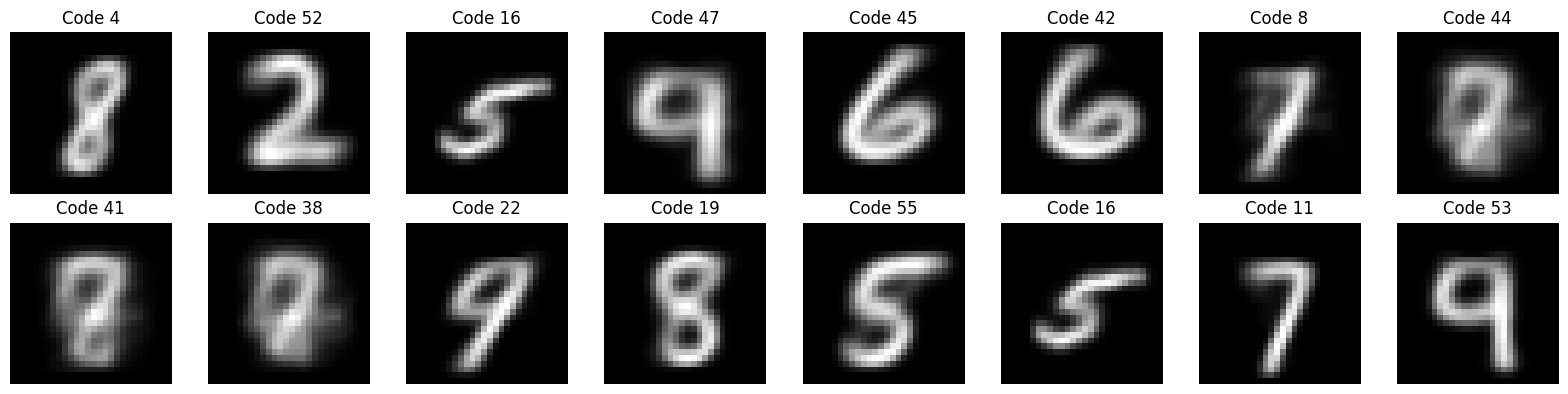

In [50]:
# Uniform samples
sample_codebook_images(best_model_VQ, n_samples=16, use_learned_dist=False)

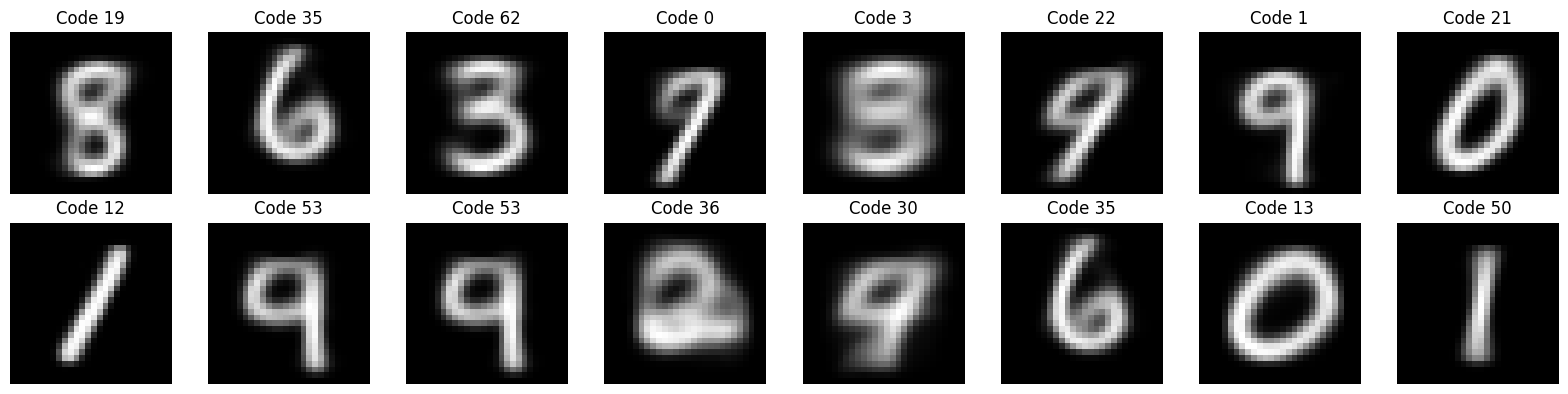

In [51]:
# Samples according to the learned distribution (codebook usage histogram)
sample_codebook_images(best_model_VQ, n_samples=16, use_learned_dist=True)